# Solar filament instance segmentation: full inference pipeline

This notebook reproduces our submission **without retraining**: it loads the committed weights from `weights/`,
runs the whole pipeline on the provided test H-alpha images, writes `submission.csv`, and reports runtime.
An optional section re-scores our held-out validation fold with an exact re-implementation of the organizers'
Panoptic Quality scorer and draws the IoU / Dice / one-to-many / many-to-one distributions.

**Pipeline:** 2048x2048 grayscale image → ensemble of 15 U-Nets (3 recipes × 5 cross-validation folds: EfficientNetV2-S @768 crops,
EfficientNetV2-S @1024 crops, ResNet34 @ full image; 3 heads: filament mask, spine, boundary) with horizontal-flip TTA, probabilities averaged → hysteresis instance grouping + thickness calibration
→ learned instance rescoring → disjoint filament masks → COCO RLE.

The competition data is not redistributed in this repo: put the Kaggle download at
`filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/` (containing `train/` and `test/`) or set `FILSEG_DATA` to that folder.
Install dependencies with `pip install -r requirements.txt`. The committed `submission.csv` is the exact file we submitted; running
section 2 regenerates it (a GPU is recommended: ~0.3 s/image).

In [1]:
import os, sys, time, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import cv2, numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from filseg.data import TEST_IMG, TRAIN_IMG, CACHE, load_index
from filseg.pipeline import Pipeline
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| test images:", TEST_IMG)

torch 2.15.0+cu132 | CUDA: True | test images: /home/Jemin/Projects/solar/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/test/test_images


## 1. Load the trained models and post-processing configuration

In [2]:
WEIGHTS = ROOT / "weights"
CKPTS = sorted(str(p) for p in WEIGHTS.glob("*.pt"))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pipe = Pipeline.from_files(CKPTS, rescorer_pkl=WEIGHTS / "rescorer.pkl", tta=("id", "h"), device=DEVICE)
print("models:", [Path(c).name for c in CKPTS])
print("post-processing:", pipe.pp.dict())
print("rescorer threshold:", pipe.rescorer and pipe.rescorer["tau"])

models: ['effv2sB_c1024_f0.pt', 'effv2sB_c1024_f1.pt', 'effv2sB_c1024_f2.pt', 'effv2sB_c1024_f3.pt', 'effv2sB_c1024_f4.pt', 'effv2s_c768_f0.pt', 'effv2s_c768_f1.pt', 'effv2s_c768_f2.pt', 'effv2s_c768_f3.pt', 'effv2s_c768_f4.pt', 'r34_full1024_f0.pt', 'r34_full1024_f1.pt', 'r34_full1024_f2.pt', 'r34_full1024_f3.pt', 'r34_full1024_f4.pt']
post-processing: {'t_low': 0.15, 't_high': 0.8, 't_shape': 0.44999999999999996, 'r_close': 1, 'dilate': 0, 'fill': True, 'min_area': 50, 'min_peak': 0.0}
rescorer threshold: 0.35


## 2. Predict the test set and write `submission.csv`

In [3]:
stems = sorted(p.stem for p in TEST_IMG.glob("*.jpeg"))
rows, t0 = [], time.time()
for s in stems:
    img = cv2.imread(str(TEST_IMG / f"{s}.jpeg"), cv2.IMREAD_GRAYSCALE)
    rows += pipe.rows(s, pipe.instances(img))
elapsed = time.time() - t0
sub = pd.DataFrame(rows, columns=["filament_id", "segmentation_rle"])
sub.to_csv(ROOT / "submission.csv", index=False)
print(f"{len(stems)} images -> {len(sub)} filaments ({len(sub)/len(stems):.1f}/image)")
print(f"end-to-end {elapsed/len(stems):.2f} s/image on {DEVICE}; per stage:", pipe.timing_summary())
sub.head()

180 images -> 1143 filaments (6.3/image)
end-to-end 6.28 s/image on cuda; per stage: {'model': 5.993, 'post': 0.092, 'rescore': 0.023}


,filament_id,segmentation_rle
0,20110120105534Ch_0,l_Vi22no12N1O2O001O001gPNIgn16XQNJin17UQNJkn1:...
1,20110120105534Ch_1,PkTo14ko11O000O2OO100000O1O01O1O2O001000O10000...
2,20110130110334Ch_0,a_hd23mo12M6K1O2M2O2N5K0101OmPN_Ogn1`0WQNAjn1k...
3,20110214175414Mh_0,X]d[27go13M3N2I7M2O2O001N1POXOhRNi0Vm1ZOgRNg0X...
4,20110214175414Mh_1,^^`d24lo11O1O00001O00001O1O1O000000000O010O100...


## 3. Validation on the held-out fold (optional, ~5 min on GPU)
Fold 0 of our date-grouped split was never used for training the three `*_f0` models, so this section uses only those (the full 15-model ensemble has seen every training image). Post-processing parameters and the rescorer were tuned on out-of-fold predictions of the other folds (honest 5-fold PQ of the full ensemble: 0.458). Each annotator of an image is a separate ground-truth entry, exactly as in the organizers' self-evaluation notebook.

model, all fold-0 images     : {'pq': 0.4723, 'sq': 0.6876, 'rq': 0.6868, 'tp': 1068, 'fp': 384, 'fn': 590, 'mean_dice_nonzero': 0.7379, 'one_to_many': 40, 'many_to_one': 37}
model, multi-annotated images: {'pq': 0.4777, 'sq': 0.6846, 'rq': 0.6978, 'tp': 635, 'fp': 245, 'fn': 305, 'mean_dice_nonzero': 0.7346, 'one_to_many': 25, 'many_to_one': 23}
annotator vs annotator (same): {'pq': 0.3328, 'sq': 0.6398, 'rq': 0.5202, 'tp': 734, 'fp': 677, 'fn': 677, 'mean_dice_nonzero': 0.6492, 'one_to_many': 54, 'many_to_one': 54}


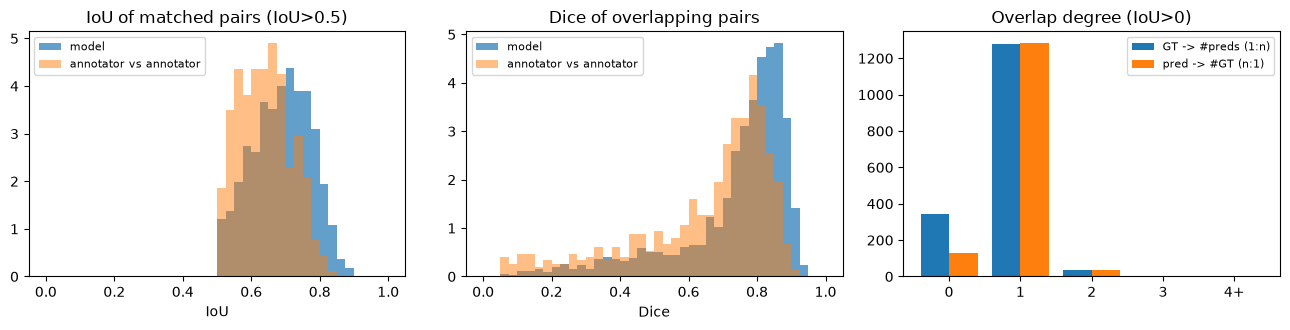

In [4]:
RUN_VALIDATION = True
if RUN_VALIDATION:
    from filseg.evaluate import load_gt, human_reference, score_labels
    from filseg.viz import plot_distributions
    val_pipe = Pipeline.from_files([c for c in CKPTS if c.endswith("_f0.pt")], rescorer_pkl=WEIGHTS / "rescorer.pkl",
                                   tta=("id", "h"), device=DEVICE)
    folds = pd.read_csv(CACHE / "folds.csv") if (CACHE / "folds.csv").exists() else pd.read_csv(ROOT / "data" / "folds.csv")
    val = folds[folds.fold == 0].stem.tolist()
    gt = load_gt(val)
    labels = {}
    for s in val:
        img = cv2.imread(str(TRAIN_IMG / f"{s}.jpeg"), cv2.IMREAD_GRAYSCALE)
        labels[s] = val_pipe.instances(img)
    model_score = score_labels(labels, gt)
    multi = [s for s in val if len(gt[s]) > 1]
    human = human_reference({s: gt[s] for s in multi})
    model_multi = score_labels({s: labels[s] for s in multi}, gt)
    print("model, all fold-0 images     :", model_score.summary())
    print("model, multi-annotated images:", model_multi.summary())
    print("annotator vs annotator (same):", human.summary())
    plot_distributions(model_score, human); plt.show()

## 4. Qualitative examples (prediction fill = colours, GT outlines = white)

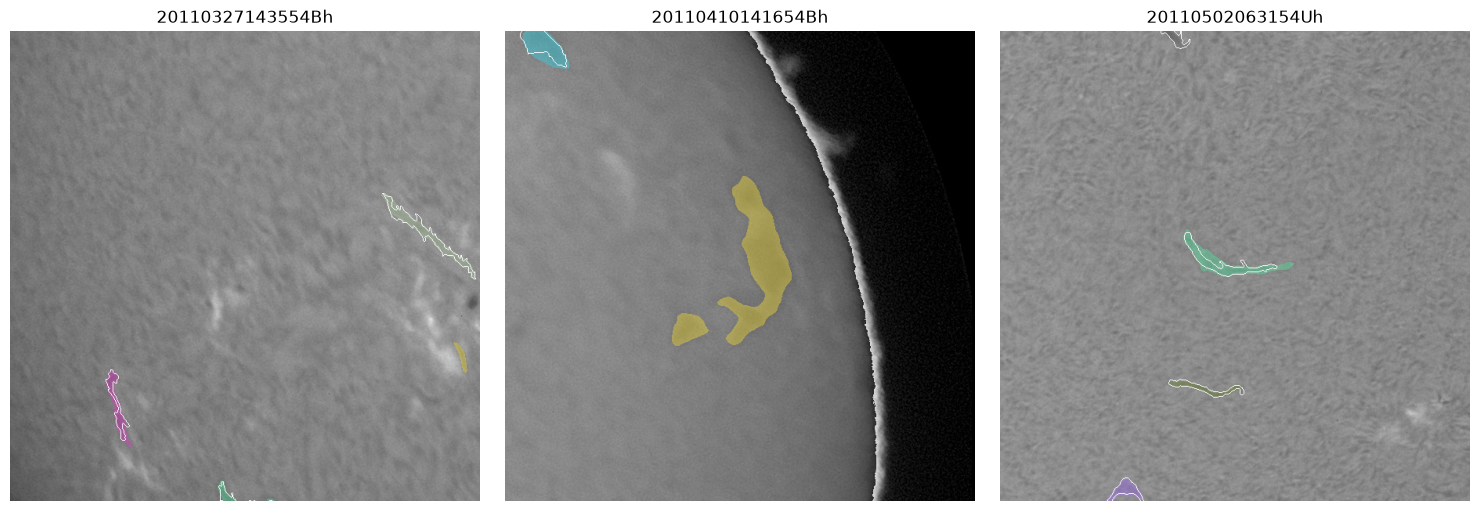

In [5]:
if RUN_VALIDATION:
    from filseg.viz import overlay
    from filseg.rle import polygon_to_mask
    idx = load_index()
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, s in zip(axes, multi[:3]):
        img = cv2.imread(str(TRAIN_IMG / f"{s}.jpeg"), cv2.IMREAD_GRAYSCALE)
        gts = [polygon_to_mask(a["segmentation"]) for a in idx[s][0].anns]
        ys, xs = np.nonzero(labels[s]) if labels[s].any() else (np.array([1024]), np.array([1024]))
        cy, cx = int(np.median(ys)), int(np.median(xs))
        crop = (max(cy - 300, 0), max(cx - 300, 0), 600, 600)
        ax.imshow(overlay(img, labels[s], gts, crop)); ax.set_title(s); ax.axis("off")
    plt.tight_layout(); plt.show()